In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

# Project root directory
PROJECT_ROOT = Path("/content/bank_marketing_project")

# Create project folders
RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
REPORTS_DIR = PROJECT_ROOT / "reports"

# Create directories
for folder in [RAW_DIR, PROCESSED_DIR, REPORTS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project workspace created!")

print("\nProject directory:", PROJECT_ROOT)
print("Raw data directory:", RAW_DIR)
print("Processed data directory:", PROCESSED_DIR)
print("Reports directory:", REPORTS_DIR)

Project workspace created!

Project directory: /content/bank_marketing_project
Raw data directory: /content/bank_marketing_project/data/raw
Processed data directory: /content/bank_marketing_project/data/processed
Reports directory: /content/bank_marketing_project/reports


## Download the original dataset

In [2]:
import urllib.request
import zipfile
import io
import hashlib

# Official UCI dataset URL
DATA_URL = (
    "https://archive.ics.uci.edu/static/public/"
    "222/bank+marketing.zip"
)

print("Starting dataset download...")

# Download ZIP archive
with urllib.request.urlopen(DATA_URL, timeout=60) as response:
    archive_data = response.read()

print("Download completed!")

print(
    "Downloaded size:",
    round(len(archive_data) / (1024 * 1024), 2),
    "MB"
)

# Inspect ZIP archive
with zipfile.ZipFile(io.BytesIO(archive_data)) as outer_zip:

    # Check archive integrity
    corrupted_file = outer_zip.testzip()

    if corrupted_file is not None:
        raise ValueError("Corrupted archive detected!")

    # Display archive contents
    files = outer_zip.namelist()

    print("\nFiles inside archive:")

    for file in files:
        print(file)

    # Find nested bank.zip
    nested_zip = next(
        (
            file for file in files
            if Path(file).name.lower() == "bank.zip"
        ),
        None
    )

    if nested_zip is None:
        raise FileNotFoundError("bank.zip not found!")

    nested_data = outer_zip.read(nested_zip)


print("\nNested bank archive found successfully!")

Starting dataset download...
Download completed!
Downloaded size: 0.98 MB

Files inside archive:
bank.zip
bank-additional.zip

Nested bank archive found successfully!


In [3]:
# Open the nested ZIP archive
with zipfile.ZipFile(io.BytesIO(nested_data)) as inner_zip:

    # Check archive integrity
    corrupted_file = inner_zip.testzip()

    if corrupted_file is not None:
        raise ValueError(f"Corrupted file: {corrupted_file}")

    # Find the original CSV
    csv_name = next(
        (
            file for file in inner_zip.namelist()
            if Path(file).name == "bank-full.csv"
        ),
        None
    )

    if csv_name is None:
        raise FileNotFoundError("bank-full.csv not found!")

    # Extract CSV bytes
    csv_data = inner_zip.read(csv_name)


# Save original CSV in raw directory
csv_path = RAW_DIR / "bank-full.csv"

csv_path.write_bytes(csv_data)

# Calculate SHA-256 checksum
file_hash = hashlib.sha256(csv_data).hexdigest()

print("Dataset extracted successfully!")
print("File location:", csv_path)
print("File size:", round(len(csv_data) / (1024 * 1024), 2), "MB")
print("SHA-256:", file_hash)

Dataset extracted successfully!
File location: /content/bank_marketing_project/data/raw/bank-full.csv
File size: 4.4 MB
SHA-256: d1513ec63b385506f7cfce9f2c5caa9fe99e7ba4e8c3fa264b3aaf0f849ed32d


In [4]:
# Load the CSV dataset
df = pd.read_csv(
    csv_path,
    sep=";"
)

# Display dataset information
print("Dataset loaded successfully!")

print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nFirst 5 Records:")
display(df.head())

print("\nLast 5 Records:")
display(df.tail())

Dataset loaded successfully!

Dataset Shape:
(45211, 17)

Column Names:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']

First 5 Records:


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no



Last 5 Records:


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
45206,51,technician,married,tertiary,no,825,no,no,cellular,17,nov,977,3,-1,0,unknown,yes
45207,71,retired,divorced,primary,no,1729,no,no,cellular,17,nov,456,2,-1,0,unknown,yes
45208,72,retired,married,secondary,no,5715,no,no,cellular,17,nov,1127,5,184,3,success,yes
45209,57,blue-collar,married,secondary,no,668,no,no,telephone,17,nov,508,4,-1,0,unknown,no
45210,37,entrepreneur,married,secondary,no,2971,no,no,cellular,17,nov,361,2,188,11,other,no


In [5]:
# 1. Dataset dimensions
print("DATASET DIMENSIONS")
print(df.shape)


# 2. Dataset information
print("\nDATASET INFORMATION")
df.info(memory_usage="deep")


# 3. Data types
print("\nCOLUMN DATA TYPES")
display(df.dtypes.to_frame(name="Data Type"))


# 4. Numerical columns
numerical_columns = df.select_dtypes(
    include=np.number
).columns.tolist()

print("\nNUMERICAL COLUMNS:")
print(numerical_columns)


# 5. Categorical columns
categorical_columns = df.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("\nCATEGORICAL COLUMNS:")
print(categorical_columns)


# 6. Dataset memory usage
memory_mb = df.memory_usage(deep=True).sum() / (1024 ** 2)

print("\nMEMORY USAGE:")
print(round(memory_mb, 2), "MB")

DATASET DIMENSIONS
(45211, 17)

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 25.7 MB

COLUMN DATA TYPES


,Data Type
age,int64
job,object
marital,object
education,object
default,object
balance,int64
housing,object
loan,object
contact,object
day,int64



NUMERICAL COLUMNS:
['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']

CATEGORICAL COLUMNS:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome', 'y']

MEMORY USAGE:
25.75 MB


In [6]:
# ==================================
# DATA QUALITY AUDIT - PART 1
# ==================================

# 1. Count missing values
missing_values = df.isnull().sum()

print("MISSING VALUES")
print(missing_values)


# 2. Calculate missing percentages
missing_percentage = (
    df.isnull().mean() * 100
)

print("\nMISSING VALUE PERCENTAGE")
print(missing_percentage.round(2))


# 3. Total missing values
total_missing = df.isnull().sum().sum()

print("\nTotal Missing Values:", total_missing)


# 4. Check duplicate records
duplicate_count = df.duplicated().sum()

print("Duplicate Records:", duplicate_count)


# 5. Check dataset dimensions
print("Dataset Shape:", df.shape)

MISSING VALUES
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

MISSING VALUE PERCENTAGE
age          0.0
job          0.0
marital      0.0
education    0.0
default      0.0
balance      0.0
housing      0.0
loan         0.0
contact      0.0
day          0.0
month        0.0
duration     0.0
campaign     0.0
pdays        0.0
previous     0.0
poutcome     0.0
y            0.0
dtype: float64

Total Missing Values: 0
Duplicate Records: 0
Dataset Shape: (45211, 17)


In [7]:
# ==================================
# DATA QUALITY AUDIT - PART 2
# ==================================

# Identify categorical columns
categorical_columns = df.select_dtypes(
    include=["object", "category"]
).columns

# Count unknown values in each categorical column
unknown_counts = {}

for column in categorical_columns:

    count = (
        df[column]
        .astype("string")
        .str.strip()
        .str.lower()
        .eq("unknown")
        .sum()
    )

    unknown_counts[column] = count


# Convert results into a DataFrame
unknown_report = pd.DataFrame(
    list(unknown_counts.items()),
    columns=["Column", "Unknown_Count"]
)

# Calculate percentage
unknown_report["Unknown_Percentage"] = (
    unknown_report["Unknown_Count"]
    / len(df) * 100
)

display(
    unknown_report.sort_values(
        by="Unknown_Count",
        ascending=False
    )
)

,Column,Unknown_Count,Unknown_Percentage
8,poutcome,36959,81.747805
6,contact,13020,28.798301
2,education,1857,4.107407
0,job,288,0.637013
1,marital,0,0.000000
3,default,0,0.000000
5,loan,0,0.000000
4,housing,0,0.000000
7,month,0,0.000000
9,y,0,0.000000


In [8]:
# =========================================
# DATA QUALITY AUDIT
# =========================================

# 1. Count actual missing values
print("MISSING VALUES PER COLUMN")

missing = df.isna().sum()

print(missing)


# 2. Total missing values
print("\nTOTAL MISSING VALUES:")

print(missing.sum())


# 3. Duplicate records
print("\nDUPLICATE RECORDS:")

print(df.duplicated().sum())


# 4. Duplicate rows including their first occurrence
print("\nALL ROWS INVOLVED IN DUPLICATES:")

duplicate_rows = df.duplicated(keep=False)

print(duplicate_rows.sum())


# 5. Percentage of duplicated records
print("\nDUPLICATE PERCENTAGE:")

print(round(df.duplicated().mean() * 100, 2), "%")

MISSING VALUES PER COLUMN
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

TOTAL MISSING VALUES:
0

DUPLICATE RECORDS:
0

ALL ROWS INVOLVED IN DUPLICATES:
0

DUPLICATE PERCENTAGE:
0.0 %


In [9]:
# Select numerical columns
numerical_columns = df.select_dtypes(
    include=np.number
).columns

# Statistical range analysis
range_report = df[numerical_columns].agg(
    ["min", "max", "mean", "std"]
).T

# Add data types
range_report["Data_Type"] = (
    df[numerical_columns].dtypes.astype(str)
)

print("NUMERICAL DATA QUALITY REPORT")

display(range_report)

NUMERICAL DATA QUALITY REPORT


,min,max,mean,std,Data_Type
age,18.0,95.0,40.936210,10.618762,int64
balance,-8019.0,102127.0,1362.272058,3044.765829,int64
day,1.0,31.0,15.806419,8.322476,int64
duration,0.0,4918.0,258.163080,257.527812,int64
campaign,1.0,63.0,2.763841,3.098021,int64
pdays,-1.0,871.0,40.197828,100.128746,int64
previous,0.0,275.0,0.580323,2.303441,int64


In [10]:
categorical_columns = df.select_dtypes(
    include="object"
).columns

for column in categorical_columns:

    print("\nColumn:", column)

    print("Unique values:")

    print(sorted(df[column].unique()))

    print("Number of categories:", df[column].nunique())


Column: job
Unique values:
['admin.', 'blue-collar', 'entrepreneur', 'housemaid', 'management', 'retired', 'self-employed', 'services', 'student', 'technician', 'unemployed', 'unknown']
Number of categories: 12

Column: marital
Unique values:
['divorced', 'married', 'single']
Number of categories: 3

Column: education
Unique values:
['primary', 'secondary', 'tertiary', 'unknown']
Number of categories: 4

Column: default
Unique values:
['no', 'yes']
Number of categories: 2

Column: housing
Unique values:
['no', 'yes']
Number of categories: 2

Column: loan
Unique values:
['no', 'yes']
Number of categories: 2

Column: contact
Unique values:
['cellular', 'telephone', 'unknown']
Number of categories: 3

Column: month
Unique values:
['apr', 'aug', 'dec', 'feb', 'jan', 'jul', 'jun', 'mar', 'may', 'nov', 'oct', 'sep']
Number of categories: 12

Column: poutcome
Unique values:
['failure', 'other', 'success', 'unknown']
Number of categories: 4

Column: y
Unique values:
['no', 'yes']
Number of ca

In [11]:
# ==========================================
# DATA VALIDATION PIPELINE
# ==========================================

validation_results = []


def add_check(name, invalid_mask, rule):

    invalid_count = int(invalid_mask.sum())

    validation_results.append({
        "Check": name,
        "Invalid_Records": invalid_count,
        "Rule": rule
    })


# ------------------------------------------
# 1. NUMERICAL VALIDATION
# ------------------------------------------

# Age: reasonable sanity limits
add_check(
    "Age",
    ~df["age"].between(18, 100),
    "Age must be between 18 and 100"
)

# Balance: negative balances are allowed
# Therefore, no negative-value rejection.

# Duration cannot be negative
add_check(
    "Duration",
    df["duration"] < 0,
    "Duration must be non-negative"
)

# Campaign must be at least 1
add_check(
    "Campaign",
    df["campaign"] < 1,
    "Campaign contacts must be at least 1"
)

# Previous contacts cannot be negative
add_check(
    "Previous",
    df["previous"] < 0,
    "Previous contacts must be non-negative"
)

# pdays: -1 is a valid special code
add_check(
    "Pdays",
    df["pdays"] < -1,
    "Pdays must be -1 or non-negative"
)


# ------------------------------------------
# 2. DATE VALIDATION
# ------------------------------------------

days_in_month = {
    "jan": 31,
    "feb": 29,
    "mar": 31,
    "apr": 30,
    "may": 31,
    "jun": 30,
    "jul": 31,
    "aug": 31,
    "sep": 30,
    "oct": 31,
    "nov": 30,
    "dec": 31
}

max_days = df["month"].map(days_in_month)

invalid_days = (
    ~df["month"].isin(days_in_month)
    | (df["day"] < 1)
    | (df["day"] > max_days.fillna(0))
)

add_check(
    "Day and Month",
    invalid_days,
    "Day must be valid for its month"
)


# ------------------------------------------
# 3. CATEGORICAL VALIDATION
# ------------------------------------------

allowed_categories = {

    "job": [
        "admin.", "blue-collar", "entrepreneur",
        "housemaid", "management", "retired",
        "self-employed", "services", "student",
        "technician", "unemployed", "unknown"
    ],

    "marital": [
        "divorced", "married", "single"
    ],

    "education": [
        "primary", "secondary", "tertiary", "unknown"
    ],

    "default": ["yes", "no"],

    "housing": ["yes", "no"],

    "loan": ["yes", "no"],

    "contact": [
        "cellular", "telephone", "unknown"
    ],

    "poutcome": [
        "failure", "other", "success", "unknown"
    ],

    "month": list(days_in_month.keys()),

    "y": ["yes", "no"]
}


for column, allowed_values in allowed_categories.items():

    invalid = ~df[column].isin(allowed_values)

    add_check(
        column,
        invalid,
        "Value must belong to the allowed categories"
    )


# ------------------------------------------
# 4. LOGICAL CONSISTENCY VALIDATION
# ------------------------------------------

# If previous contacts = 0,
# pdays should normally equal -1.
# If previous contacts > 0,
# pdays should be non-negative.

invalid_contact_history = (
    ((df["previous"] == 0) & (df["pdays"] != -1))
    |
    ((df["previous"] > 0) & (df["pdays"] < 0))
)

add_check(
    "Contact History",
    invalid_contact_history,
    "Previous contacts and pdays must be consistent"
)


# ------------------------------------------
# 5. DISPLAY VALIDATION REPORT
# ------------------------------------------

validation_df = pd.DataFrame(validation_results)

display(validation_df)

print("\nTOTAL RULE VIOLATIONS:")

print(validation_df["Invalid_Records"].sum())

,Check,Invalid_Records,Rule
0,Age,0,Age must be between 18 and 100
1,Duration,0,Duration must be non-negative
2,Campaign,0,Campaign contacts must be at least 1
3,Previous,0,Previous contacts must be non-negative
4,Pdays,0,Pdays must be -1 or non-negative
5,Day and Month,0,Day must be valid for its month
6,job,0,Value must belong to the allowed categories
7,marital,0,Value must belong to the allowed categories
8,education,0,Value must belong to the allowed categories
9,default,0,Value must belong to the allowed categories



TOTAL RULE VIOLATIONS:
0


In [12]:
# ==========================================
# OUTLIER DETECTION USING IQR
# ==========================================

outlier_columns = [
    "age",
    "balance",
    "duration",
    "campaign",
    "previous"
]

outlier_results = []

for column in outlier_columns:

    # Select column data
    values = df[column].dropna()

    # Calculate quartiles
    Q1 = values.quantile(0.25)
    Q3 = values.quantile(0.75)

    # Calculate IQR
    IQR = Q3 - Q1

    # Calculate boundaries
    lower_fence = Q1 - 1.5 * IQR
    upper_fence = Q3 + 1.5 * IQR

    # Identify outliers
    outliers = values[
        (values < lower_fence) |
        (values > upper_fence)
    ]

    # Store results
    outlier_results.append({
        "Feature": column,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower_Fence": lower_fence,
        "Upper_Fence": upper_fence,
        "Outlier_Count": len(outliers),
        "Outlier_Percentage": (
            len(outliers) / len(values) * 100
        )
    })


# Create report
outlier_report = pd.DataFrame(outlier_results)

display(outlier_report.round(2))

,Feature,Q1,Q3,IQR,Lower_Fence,Upper_Fence,Outlier_Count,Outlier_Percentage
0,age,33.0,48.0,15.0,10.5,70.5,487,1.08
1,balance,72.0,1428.0,1356.0,-1962.0,3462.0,4729,10.46
2,duration,103.0,319.0,216.0,-221.0,643.0,3235,7.16
3,campaign,1.0,3.0,2.0,-2.0,6.0,3064,6.78
4,previous,0.0,0.0,0.0,0.0,0.0,8257,18.26


In [13]:
outlier_columns = [
    "age",
    "balance",
    "duration",
    "campaign",
    "previous"
]

outlier_details = []

for column in outlier_columns:

    values = df[column]

    Q1 = values.quantile(0.25)
    Q3 = values.quantile(0.75)

    IQR = Q3 - Q1

    lower_fence = Q1 - 1.5 * IQR
    upper_fence = Q3 + 1.5 * IQR

    lower_count = (values < lower_fence).sum()
    upper_count = (values > upper_fence).sum()

    outlier_details.append({
        "Feature": column,
        "Lower_Fence": lower_fence,
        "Upper_Fence": upper_fence,
        "Lower_Outliers": lower_count,
        "Upper_Outliers": upper_count
    })

outlier_details_df = pd.DataFrame(outlier_details)

display(outlier_details_df)

,Feature,Lower_Fence,Upper_Fence,Lower_Outliers,Upper_Outliers
0,age,10.5,70.5,0,487
1,balance,-1962.0,3462.0,17,4712
2,duration,-221.0,643.0,0,3235
3,campaign,-2.0,6.0,0,3064
4,previous,0.0,0.0,0,8257


In [14]:
# Inspect 10 smallest and largest values
for column in outlier_columns:

    print("\nFEATURE:", column)
    print("=" * 50)

    print("\nSmallest 10 values:")

    display(
        df.nsmallest(10, column)[
            [column, "age", "job", "balance", "y"]
        ]
    )

    print("\nLargest 10 values:")

    display(
        df.nlargest(10, column)[
            [column, "age", "job", "balance", "y"]
        ]
    )


FEATURE: age

Smallest 10 values:


,age,age,job,balance,y
40736,18,18,student,1944,no
40744,18,18,student,108,yes
40887,18,18,student,608,yes
41222,18,18,student,35,no
41252,18,18,student,5,no
41273,18,18,student,3,yes
41487,18,18,student,108,yes
42146,18,18,student,156,no
42274,18,18,student,608,yes
42954,18,18,student,108,yes



Largest 10 values:


,age,age,job,balance,y
33699,95,95,retired,2282,yes
41663,95,95,retired,0,no
31233,94,94,retired,1234,no
44262,93,93,retired,775,yes
44420,93,93,retired,775,yes
41934,92,92,retired,775,yes
42727,92,92,retired,775,yes
31069,90,90,retired,1,yes
43194,90,90,retired,712,yes
41162,89,89,retired,553,no



FEATURE: balance

Smallest 10 values:


,balance,age,job,balance,y
12909,-8019,26,blue-collar,-8019,no
15682,-6847,49,management,-6847,no
38736,-4057,60,management,-4057,no
7413,-3372,43,management,-3372,no
1896,-3313,57,self-employed,-3313,no
32713,-3058,39,self-employed,-3058,yes
18573,-2827,40,technician,-2827,no
31509,-2712,52,management,-2712,no
25119,-2604,49,blue-collar,-2604,no
14434,-2282,51,management,-2282,no


... (10 outputs left out)


FEATURE: previous

Smallest 10 values:


,previous,age,job,balance,y
0,0,58,management,2143,no
1,0,44,technician,29,no
2,0,33,entrepreneur,2,no
3,0,47,blue-collar,1506,no
4,0,33,unknown,1,no
5,0,35,management,231,no
6,0,28,management,447,no
7,0,42,entrepreneur,2,no
8,0,58,retired,121,no
9,0,43,technician,593,no



Largest 10 values:


,previous,age,job,balance,y
29182,275,40,management,543,no
38326,58,46,blue-collar,1085,yes
44089,55,37,technician,432,yes
28886,51,31,management,358,no
44822,41,27,blue-collar,821,no
42611,40,35,technician,4645,no
28498,38,49,management,145,no
37567,38,39,management,0,no
26668,37,51,entrepreneur,653,no
42422,37,27,student,91,no


In [15]:
print("PREVIOUS CONTACT DISTRIBUTION")

print(df["previous"].value_counts().sort_index().head(20))

print("\nPercentage of customers with zero previous contacts:")

zero_percentage = (
    (df["previous"] == 0).mean() * 100
)

print(round(zero_percentage, 2), "%")


print("\nCustomers with previous contacts:")

print((df["previous"] > 0).sum())

PREVIOUS CONTACT DISTRIBUTION
previous
0     36954
1      2772
2      2106
3      1142
4       714
5       459
6       277
7       205
8       129
9        92
10       67
11       65
12       44
13       38
14       19
15       20
16       13
17       15
18        6
19       11
Name: count, dtype: int64

Percentage of customers with zero previous contacts:
81.74 %

Customers with previous contacts:
8257


In [16]:
# Columns for outlier investigation
outlier_columns = [
    "age",
    "balance",
    "duration",
    "campaign"
]

outlier_details = []

for column in outlier_columns:

    values = df[column].dropna()

    # Calculate quartiles
    Q1 = values.quantile(0.25)
    Q3 = values.quantile(0.75)

    # Calculate IQR
    IQR = Q3 - Q1

    # Calculate boundaries
    lower_fence = Q1 - 1.5 * IQR
    upper_fence = Q3 + 1.5 * IQR

    # Count lower outliers
    lower_count = (values < lower_fence).sum()

    # Count upper outliers
    upper_count = (values > upper_fence).sum()

    # Store results
    outlier_details.append({
        "Feature": column,
        "Lower_Fence": lower_fence,
        "Upper_Fence": upper_fence,
        "Lower_Outliers": lower_count,
        "Upper_Outliers": upper_count
    })


# Create report
outlier_details_df = pd.DataFrame(outlier_details)

display(outlier_details_df.round(2))

,Feature,Lower_Fence,Upper_Fence,Lower_Outliers,Upper_Outliers
0,age,10.5,70.5,0,487
1,balance,-1962.0,3462.0,17,4712
2,duration,-221.0,643.0,0,3235
3,campaign,-2.0,6.0,0,3064


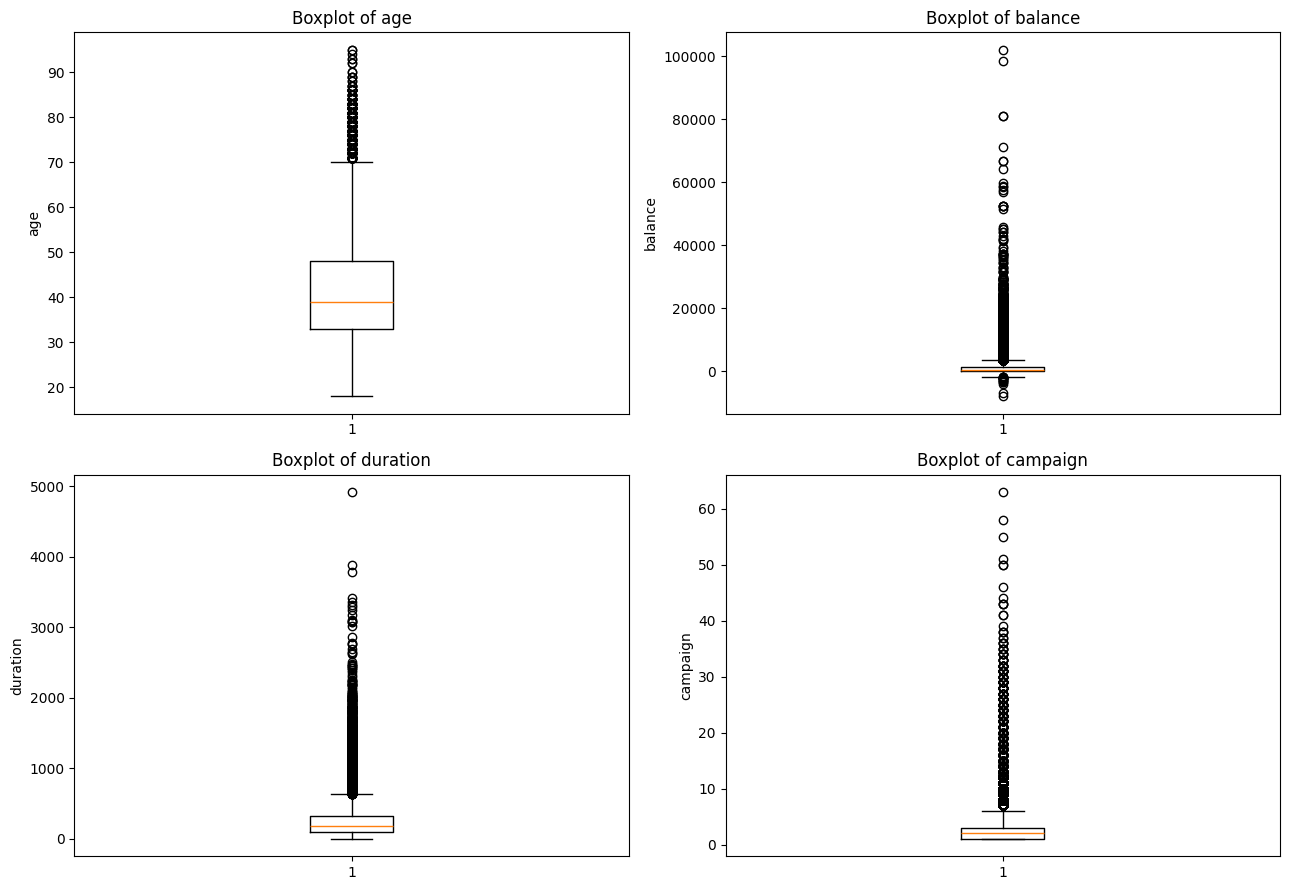

In [17]:
import matplotlib.pyplot as plt

outlier_columns = [
    "age",
    "balance",
    "duration",
    "campaign"
]

fig, axes = plt.subplots(
    2, 2,
    figsize=(13, 9)
)

axes = axes.flatten()

for i, column in enumerate(outlier_columns):

    axes[i].boxplot(df[column].dropna())

    axes[i].set_title(f"Boxplot of {column}")
    axes[i].set_ylabel(column)

plt.tight_layout()
plt.show()

In [18]:
# Columns to investigate
columns_to_check = ["balance", "duration", "campaign"]

for column in columns_to_check:

    print("\nFEATURE:", column)
    print("=" * 50)

    context = [
        column,
        "age",
        "job",
        "balance",
        "campaign",
        "previous",
        "y"
    ]

    # Remove duplicate column names
    context = list(dict.fromkeys(context))

    print("\n10 Smallest Observations:")

    display(
        df.nsmallest(10, column)[context]
    )

    print("\n10 Largest Observations:")

    display(
        df.nlargest(10, column)[context]
    )


FEATURE: balance

10 Smallest Observations:


,balance,age,job,campaign,previous,y
12909,-8019,26,blue-collar,3,0,no
15682,-6847,49,management,1,0,no
38736,-4057,60,management,6,0,no
7413,-3372,43,management,2,0,no
1896,-3313,57,self-employed,1,0,no
32713,-3058,39,self-employed,3,0,yes
18573,-2827,40,technician,1,0,no
31509,-2712,52,management,1,0,no
25119,-2604,49,blue-collar,1,0,no
14434,-2282,51,management,6,0,no



10 Largest Observations:


,balance,age,job,campaign,previous,y
39989,102127,51,management,1,0,no
26227,98417,59,management,5,0,no
42558,81204,84,retired,1,2,yes
43393,81204,84,retired,1,3,yes
41693,71188,60,retired,1,0,no
19785,66721,56,management,2,0,no
21192,66653,52,blue-collar,3,0,no
19420,64343,59,admin.,4,0,no
41374,59649,32,entrepreneur,2,0,no
12926,58932,56,blue-collar,2,0,no



FEATURE: duration

10 Smallest Observations:


,duration,age,job,balance,campaign,previous,y
6424,0,53,management,351,4,0,no
22937,0,35,technician,5535,15,0,no
36425,0,31,entrepreneur,162,2,0,no
31740,1,39,technician,17441,1,0,no
44758,1,28,admin.,1595,1,4,no
287,2,50,technician,339,3,0,no
24994,2,36,blue-collar,871,1,0,no
30278,2,54,unemployed,925,1,0,no
2177,3,43,blue-collar,0,1,0,no
2599,3,35,technician,304,1,0,no


... (2 outputs left out)


FEATURE: campaign

10 Smallest Observations:


,campaign,age,job,balance,previous,y
0,1,58,management,2143,0,no
1,1,44,technician,29,0,no
2,1,33,entrepreneur,2,0,no
3,1,47,blue-collar,1506,0,no
4,1,33,unknown,1,0,no
5,1,35,management,231,0,no
6,1,28,management,447,0,no
7,1,42,entrepreneur,2,0,no
8,1,58,retired,121,0,no
9,1,43,technician,593,0,no



10 Largest Observations:


,campaign,age,job,balance,previous,y
4330,63,45,management,9051,0,no
11914,58,24,technician,126,0,no
5073,55,35,technician,432,0,no
4299,51,30,management,358,0,no
5459,50,35,blue-collar,430,0,no
18713,50,35,blue-collar,280,0,no
10697,46,28,blue-collar,235,0,no
18744,44,49,blue-collar,371,0,no
4275,43,40,blue-collar,-365,0,no
13675,43,51,blue-collar,41,0,no


In [19]:
  # Frequency distribution
previous_counts = (
    df["previous"]
    .value_counts()
    .sort_index()
)

print("Previous Contact Distribution:")

display(previous_counts.head(20))


# Calculate zero-contact percentage
zero_percentage = (
    (df["previous"] == 0).mean() * 100
)

print(
    "\nPercentage with zero previous contacts:",
    round(zero_percentage, 2),
    "%"
)


# Count customers with previous contacts
positive_contacts = (
    df["previous"] > 0
).sum()

print(
    "Customers with previous contacts:",
    positive_contacts
)

Previous Contact Distribution:


,count
previous,
0,36954
1,2772
2,2106
3,1142
4,714
5,459
6,277
7,205
8,129



Percentage with zero previous contacts: 81.74 %
Customers with previous contacts: 8257


In [20]:
# Compare previous contacts with previous campaign outcome

cross_table = pd.crosstab(
    df["previous"],
    df["poutcome"]
)

print("PREVIOUS CONTACTS VS CAMPAIGN OUTCOME")

display(cross_table)


# Investigate zero previous contacts
zero_previous = df[df["previous"] == 0]

print("\nZERO PREVIOUS CONTACTS")

display(zero_previous["poutcome"].value_counts())


# Investigate positive previous contacts
positive_previous = df[df["previous"] > 0]

print("\nPOSITIVE PREVIOUS CONTACTS")

display(positive_previous["poutcome"].value_counts())

PREVIOUS CONTACTS VS CAMPAIGN OUTCOME


poutcome,failure,other,success,unknown
previous,,,,
0,0,0,0,36954
1,1707,591,473,1
2,1362,390,352,2
3,660,238,244,0
4,405,165,144,0
5,261,107,90,1
6,146,64,67,0
7,101,59,44,1
8,54,46,29,0



ZERO PREVIOUS CONTACTS


,count
poutcome,
unknown,36954



POSITIVE PREVIOUS CONTACTS


,count
poutcome,
failure,4901
other,1840
success,1511
unknown,5


In [21]:

# Count calls with zero duration
zero_duration_count = (df["duration"] == 0).sum()

# Calculate their percentage in the complete dataset
zero_duration_percentage = (df["duration"] == 0).mean() * 100

print("Zero-duration calls:", zero_duration_count)
print("Percentage:", round(zero_duration_percentage, 2), "%")

# Inspect some records with zero duration
zero_duration_records = df.loc[
    df["duration"] == 0,
    ["age", "job", "contact", "campaign", "y"]
]

display(zero_duration_records.head(10))


Zero-duration calls: 3
Percentage: 0.01 %


,age,job,contact,campaign,y
6424,53,management,unknown,4,no
22937,35,technician,cellular,15,no
36425,31,entrepreneur,cellular,2,no


In [22]:

# Create a separate copy so the original dataset remains unchanged
df_clean = df.copy()

# Record our data-cleaning decisions
cleaning_decisions = pd.DataFrame({
    "Issue": [
        "Missing values",
        "Duplicate records",
        "Unknown categories",
        "Outliers",
        "Zero previous contacts",
        "Zero-duration calls",
        "Duration feature"
    ],
    "Finding": [
        "No missing values",
        "No duplicate records",
        "Present in several categorical columns",
        "Some extreme but potentially valid values",
        "Valid observations",
        "Only 3 records (0.01%)",
        "Known only after the call"
    ],
    "Decision": [
        "No removal required",
        "No removal required",
        "Preserve as a category",
        "Keep for now",
        "Keep",
        "Keep",
        "Exclude from pre-call model features"
    ]
})

display(cleaning_decisions)
print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)


,Issue,Finding,Decision
0,Missing values,No missing values,No removal required
1,Duplicate records,No duplicate records,No removal required
2,Unknown categories,Present in several categorical columns,Preserve as a category
3,Outliers,Some extreme but potentially valid values,Keep for now
4,Zero previous contacts,Valid observations,Keep
5,Zero-duration calls,Only 3 records (0.01%),Keep
6,Duration feature,Known only after the call,Exclude from pre-call model features


Original dataset shape: (45211, 17)
Cleaned dataset shape: (45211, 17)


In [23]:

# Separate input features (X) and target (y)

# Remove the target and duration from the input features
X = df_clean.drop(columns=["y", "duration"])

# Keep the target column separately
y = df_clean["y"]

# Inspect the results
print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

print("\nTarget distribution:")
display(y.value_counts())


Features shape: (45211, 15)
Target shape: (45211,)

Feature columns:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'campaign', 'pdays', 'previous', 'poutcome']

Target distribution:


,count
y,
no,39922
yes,5289


,Count,Percentage
y,,
no,39922,88.3
yes,5289,11.7


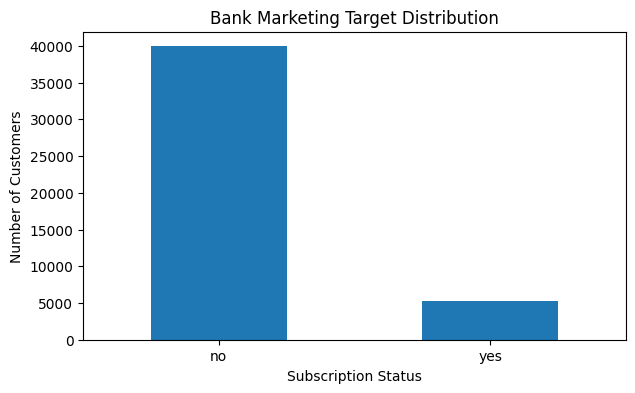

In [24]:

# Count each target class
target_counts = y.value_counts()

# Calculate the percentage of each class
target_percentages = y.value_counts(normalize=True) * 100

# Combine counts and percentages into one report
target_summary = pd.DataFrame({
    "Count": target_counts,
    "Percentage": target_percentages.round(2)
})

display(target_summary)

# Visualize the target distribution
plt.figure(figsize=(7, 4))

target_counts.plot(kind="bar")

plt.title("Bank Marketing Target Distribution")
plt.xlabel("Subscription Status")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)

plt.show()


In [25]:

# Import the train_test_split function
from sklearn.model_selection import train_test_split

# Split features and target into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Check the shapes of all four datasets
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

# Compare target distribution in training and testing sets
split_summary = pd.DataFrame({
    "Train Count": y_train.value_counts(),
    "Test Count": y_test.value_counts(),
    "Train Percentage": y_train.value_counts(normalize=True) * 100,
    "Test Percentage": y_test.value_counts(normalize=True) * 100
})

display(split_summary.round(2))


X_train shape: (36168, 15)
X_test shape: (9043, 15)
y_train shape: (36168,)
y_test shape: (9043,)


,Train Count,Test Count,Train Percentage,Test Percentage
y,,,,
no,31937,7985,88.3,88.3
yes,4231,1058,11.7,11.7


In [26]:

# Identify numerical columns from training features
numerical_columns = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

# Identify categorical columns from training features
categorical_columns = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

# Display numerical columns
print("Numerical columns:")
print(numerical_columns)

# Display categorical columns
print("\nCategorical columns:")
print(categorical_columns)

# Count each type
print("\nTotal numerical columns:", len(numerical_columns))
print("Total categorical columns:", len(categorical_columns))


Numerical columns:
['age', 'balance', 'day', 'campaign', 'pdays', 'previous']

Categorical columns:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

Total numerical columns: 6
Total categorical columns: 9


In [27]:

# Count unique categories in each categorical feature
category_counts = X_train[categorical_columns].nunique()

# Sort the results from highest to lowest
category_counts = category_counts.sort_values(
    ascending=False
)

print("Unique categories per feature:")
display(category_counts.to_frame(name="Unique Categories"))

# Estimate the total number of columns OneHotEncoder may create
print(
    "Potential one-hot encoded columns:",
    category_counts.sum()
)


Unique categories per feature:


,Unique Categories
job,12
month,12
education,4
poutcome,4
marital,3
contact,3
default,2
housing,2
loan,2


Potential one-hot encoded columns: 44


In [28]:

# Import preprocessing tools
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# Create numerical preprocessing transformer
numeric_transformer = StandardScaler()

# Create categorical preprocessing transformer
categorical_transformer = OneHotEncoder(
    handle_unknown="ignore"
)

# Combine both transformers
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_columns),
        ("cat", categorical_transformer, categorical_columns)
    ]
)

# Learn preprocessing rules from training data and transform it
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the learned rules to testing data
X_test_processed = preprocessor.transform(X_test)

# Inspect the transformed datasets
print("Training data shape:", X_train_processed.shape)
print("Testing data shape:", X_test_processed.shape)

# Inspect transformed feature names
feature_names = preprocessor.get_feature_names_out()

print("\nTotal transformed features:", len(feature_names))
print("\nFirst 20 transformed feature names:")
print(feature_names[:20])


Training data shape: (36168, 50)
Testing data shape: (9043, 50)

Total transformed features: 50

First 20 transformed feature names:
['num__age' 'num__balance' 'num__day' 'num__campaign' 'num__pdays'
 'num__previous' 'cat__job_admin.' 'cat__job_blue-collar'
 'cat__job_entrepreneur' 'cat__job_housemaid' 'cat__job_management'
 'cat__job_retired' 'cat__job_self-employed' 'cat__job_services'
 'cat__job_student' 'cat__job_technician' 'cat__job_unemployed'
 'cat__job_unknown' 'cat__marital_divorced' 'cat__marital_married']


In [29]:

# Import the SciPy sparse matrix utility
from scipy import sparse

# Check the data structure returned by our preprocessor
print("Data type:", type(X_train_processed))

# Check whether our output is a sparse matrix
print("Is sparse matrix:", sparse.issparse(X_train_processed))

# Convert only the first 5 records into a dense array
if sparse.issparse(X_train_processed):
    sample_data = X_train_processed[:5].toarray()
else:
    sample_data = X_train_processed[:5]

# Convert the sample into a readable DataFrame
processed_sample = pd.DataFrame(
    sample_data,
    columns=feature_names
)

# Display the first 5 processed records
display(processed_sample)


Data type: <class 'numpy.ndarray'>
Is sparse matrix: False


,num__age,num__balance,num__day,num__campaign,num__pdays,num__previous,cat__job_admin.,cat__job_blue-collar,cat__job_entrepreneur,cat__job_housemaid,...,cat__month_jun,cat__month_mar,cat__month_may,cat__month_nov,cat__month_oct,cat__month_sep,cat__poutcome_failure,cat__poutcome_other,cat__poutcome_success,cat__poutcome_unknown
0,-0.460434,-0.164410,1.582124,-0.246104,-0.410910,-0.241509,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,-1.589641,0.899627,-1.298384,0.398202,1.446096,2.664584,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
2,0.292371,-0.365486,-0.458236,0.398202,-0.410910,-0.241509,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
3,0.668773,-0.445003,1.822166,2.653271,-0.410910,-0.241509,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
4,-0.272233,-0.361249,1.222060,2.331118,-0.410910,-0.241509,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


In [30]:
# Import PyTorch
import torch
import torch.nn as nn
import torch.optim as optim

# Convert training features into PyTorch tensors
X_train_tensor = torch.tensor(
    X_train_processed,
    dtype=torch.float32
)

# Convert testing features into PyTorch tensors
X_test_tensor = torch.tensor(
    X_test_processed,
    dtype=torch.float32
)

# Convert target labels: no = 0, yes = 1
y_train_tensor = torch.tensor(
    y_train.map({"no": 0, "yes": 1}).to_numpy(),
    dtype=torch.float32
).view(-1, 1)

y_test_tensor = torch.tensor(
    y_test.map({"no": 0, "yes": 1}).to_numpy(),
    dtype=torch.float32
).view(-1, 1)

# Inspect the tensors
print("Training features:", X_train_tensor.shape)
print("Training labels:", y_train_tensor.shape)

print("Testing features:", X_test_tensor.shape)
print("Testing labels:", y_test_tensor.shape)

print("Feature data type:", X_train_tensor.dtype)
print("Target data type:", y_train_tensor.dtype)

Training features: torch.Size([36168, 50])
Training labels: torch.Size([36168, 1])
Testing features: torch.Size([9043, 50])
Testing labels: torch.Size([9043, 1])
Feature data type: torch.float32
Target data type: torch.float32


In [31]:
# Define our Logistic Regression model
class LogisticRegressionModel(nn.Module):

    def __init__(self, input_features):
        super().__init__()

        # Linear layer: 50 inputs and 1 output
        self.linear = nn.Linear(input_features, 1)

    # Define the forward pass
    def forward(self, x):

        # Calculate the linear output
        z = self.linear(x)

        # Apply sigmoid activation
        prediction = torch.sigmoid(z)

        return prediction


# Create the model
model = LogisticRegressionModel(input_features=50)

# Test the model with 5 training examples
sample_predictions = model(X_train_tensor[:5])

# Inspect the architecture and predictions
print(model)

print("\nModel predictions:")
print(sample_predictions)

print("\nPrediction shape:", sample_predictions.shape)

LogisticRegressionModel(
  (linear): Linear(in_features=50, out_features=1, bias=True)
)

Model predictions:
tensor([[0.4379],
        [0.5032],
        [0.5174],
        [0.4835],
        [0.4224]], grad_fn=<SigmoidBackward0>)

Prediction shape: torch.Size([5, 1])


In [32]:
# Define Binary Cross Entropy loss
loss_function = nn.BCELoss()

# Define Stochastic Gradient Descent optimizer
optimizer = optim.SGD(
    model.parameters(),
    lr=0.01
)

# Inspect our training configuration
print("Loss function:", loss_function)
print("Optimizer:", optimizer)
print("Learning rate:", optimizer.param_groups[0]["lr"])

# Count trainable parameters
total_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print("Trainable parameters:", total_parameters)

Loss function: BCELoss()
Optimizer: SGD (
Parameter Group 0
    dampening: 0
    differentiable: False
    foreach: None
    fused: None
    lr: 0.01
    maximize: False
    momentum: 0
    nesterov: False
    weight_decay: 0
)
Learning rate: 0.01
Trainable parameters: 51


In [33]:
# Import DataLoader and TensorDataset
from torch.utils.data import TensorDataset, DataLoader

# Combine features and labels into one dataset
train_dataset = TensorDataset(
    X_train_tensor,
    y_train_tensor
)

# Create batches for training
train_loader = DataLoader(
    dataset=train_dataset,
    batch_size=256,
    shuffle=True
)

# Inspect the dataset and batches
print("Total training records:", len(train_dataset))
print("Batch size:", train_loader.batch_size)
print("Number of batches:", len(train_loader))

Total training records: 36168
Batch size: 256
Number of batches: 142


In [34]:
# Number of complete passes through the training dataset
num_epochs = 30

# Store the loss from each epoch
training_losses = []

# Start training
for epoch in range(num_epochs):

    # Set the model to training mode
    model.train()

    # Reset total loss for this epoch
    total_loss = 0.0

    # Iterate through all mini-batches
    for batch_features, batch_labels in train_loader:

        # Clear gradients from the previous batch
        optimizer.zero_grad()

        # Forward pass: generate predictions
        predictions = model(batch_features)

        # Calculate prediction error
        loss = loss_function(predictions, batch_labels)

        # Backward pass: calculate gradients
        loss.backward()

        # Update weights and bias
        optimizer.step()

        # Accumulate the loss for this batch
        total_loss += loss.item() * batch_features.size(0)

    # Calculate average loss for the entire epoch
    epoch_loss = total_loss / len(train_dataset)

    # Save the average loss
    training_losses.append(epoch_loss)

    # Display progress every 5 epochs
    if (epoch + 1) % 5 == 0:
        print(f"Epoch [{epoch + 1}/{num_epochs}], Loss: {epoch_loss:.4f}")

print("\nTraining completed!")

Epoch [5/30], Loss: 0.3369
Epoch [10/30], Loss: 0.3267
Epoch [15/30], Loss: 0.3217
Epoch [20/30], Loss: 0.3186
Epoch [25/30], Loss: 0.3164
Epoch [30/30], Loss: 0.3147

Training completed!


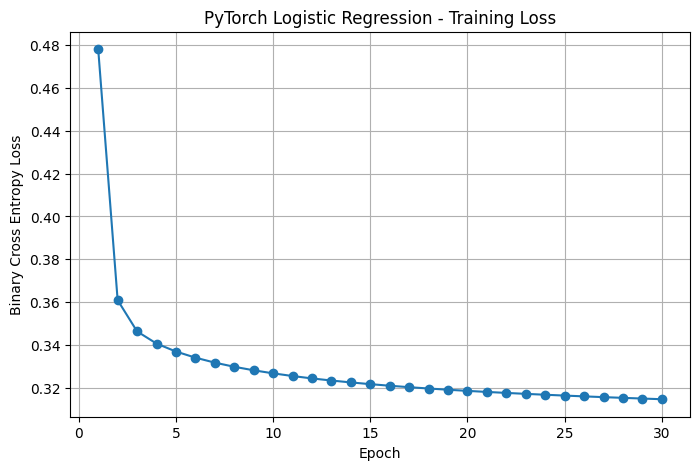

In [35]:
# Plot training loss
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, num_epochs + 1),
    training_losses,
    marker="o"
)

plt.title("PyTorch Logistic Regression - Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross Entropy Loss")

plt.grid(True)
plt.show()

In [36]:
# Put the model into evaluation mode
model.eval()

# Disable gradient calculations during prediction
with torch.no_grad():

    # Generate probabilities for test customers
    y_test_probs = model(X_test_tensor)

    # Convert probabilities into binary predictions
    y_test_pred = (y_test_probs >= 0.5).int()

# Display the first 10 predictions
prediction_results = pd.DataFrame({
    "Probability": y_test_probs[:10].squeeze().numpy(),
    "Predicted": y_test_pred[:10].squeeze().numpy(),
    "Actual": y_test_tensor[:10].squeeze().numpy()
})

# Convert numerical labels back to understandable categories
prediction_results["Predicted"] = prediction_results["Predicted"].map({
    0: "no",
    1: "yes"
})

prediction_results["Actual"] = prediction_results["Actual"].map({
    0: "no",
    1: "yes"
})

display(prediction_results)

,Probability,Predicted,Actual
0,0.025344,no,no
1,0.030584,no,no
2,0.031497,no,no
3,0.025481,no,no
4,0.109846,no,no
5,0.045896,no,no
6,0.111174,no,no
7,0.513300,yes,yes
8,0.172380,no,no
9,0.205673,no,no


In [37]:
# Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

# Convert PyTorch tensors into NumPy arrays
y_true = y_test_tensor.numpy().ravel().astype(int)
y_pred = y_test_pred.numpy().ravel().astype(int)

# Calculate accuracy
accuracy = accuracy_score(y_true, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

# Generate confusion matrix
cm = confusion_matrix(y_true, y_pred)

print("\nConfusion Matrix:")
print(cm)

# Generate detailed classification report
print("\nClassification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        target_names=["no", "yes"],
        zero_division=0
    )
)

Model Accuracy: 88.59 %

Confusion Matrix:
[[7970   15]
 [1017   41]]

Classification Report:
              precision    recall  f1-score   support

          no       0.89      1.00      0.94      7985
         yes       0.73      0.04      0.07      1058

    accuracy                           0.89      9043
   macro avg       0.81      0.52      0.51      9043
weighted avg       0.87      0.89      0.84      9043



In [38]:
# Put the model into evaluation mode
model.eval()

# Calculate loss without tracking gradients
with torch.no_grad():

    # Predictions on training data
    train_predictions = model(X_train_tensor)

    # Predictions on test data
    test_predictions = model(X_test_tensor)

    # Calculate BCE loss for both datasets
    final_train_loss = loss_function(
        train_predictions,
        y_train_tensor
    )

    test_loss = loss_function(
        test_predictions,
        y_test_tensor
    )

# Display results
print("Final Training Loss:", round(final_train_loss.item(), 4))
print("Test Loss:", round(test_loss.item(), 4))

Final Training Loss: 0.3145
Test Loss: 0.3114


In [39]:
from sklearn.model_selection import train_test_split

# Split existing training data into training and validation sets
X_fit_raw, X_val_raw, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

# Inspect dataset sizes
print("Model training records:", len(X_fit_raw))
print("Validation records:", len(X_val_raw))

print("\nTraining target distribution:")
print(y_fit.value_counts())

print("\nValidation target distribution:")
print(y_val.value_counts())

Model training records: 28934
Validation records: 7234

Training target distribution:
y
no     25549
yes     3385
Name: count, dtype: int64

Validation target distribution:
y
no     6388
yes     846
Name: count, dtype: int64


In [40]:
# Create a fresh preprocessing pipeline
preprocessor_v2 = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_columns),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_columns)
    ]
)

# Learn preprocessing parameters using training data only
X_fit_processed = preprocessor_v2.fit_transform(X_fit_raw)

# Apply the same preprocessing to validation and test data
X_val_processed = preprocessor_v2.transform(X_val_raw)
X_test_v2_processed = preprocessor_v2.transform(X_test)

# Handle sparse matrices if necessary
from scipy import sparse

if sparse.issparse(X_fit_processed):
    X_fit_processed = X_fit_processed.toarray()

if sparse.issparse(X_val_processed):
    X_val_processed = X_val_processed.toarray()

if sparse.issparse(X_test_v2_processed):
    X_test_v2_processed = X_test_v2_processed.toarray()

# Inspect the results
print("Training features:", X_fit_processed.shape)
print("Validation features:", X_val_processed.shape)
print("Testing features:", X_test_v2_processed.shape)


Training features: (28934, 50)
Validation features: (7234, 50)
Testing features: (9043, 50)


In [41]:
# Convert training features
X_fit_tensor = torch.tensor(
    X_fit_processed,
    dtype=torch.float32
)

# Convert validation features
X_val_tensor = torch.tensor(
    X_val_processed,
    dtype=torch.float32
)

# Convert final testing features
X_test_v2_tensor = torch.tensor(
    X_test_v2_processed,
    dtype=torch.float32
)

# Convert target labels: no = 0, yes = 1
y_fit_tensor = torch.tensor(
    y_fit.map({"no": 0, "yes": 1}).to_numpy(),
    dtype=torch.float32
).view(-1, 1)

y_val_tensor = torch.tensor(
    y_val.map({"no": 0, "yes": 1}).to_numpy(),
    dtype=torch.float32
).view(-1, 1)

y_test_v2_tensor = torch.tensor(
    y_test.map({"no": 0, "yes": 1}).to_numpy(),
    dtype=torch.float32
).view(-1, 1)

# Inspect tensor shapes
print("Training:", X_fit_tensor.shape, y_fit_tensor.shape)
print("Validation:", X_val_tensor.shape, y_val_tensor.shape)
print("Testing:", X_test_v2_tensor.shape, y_test_v2_tensor.shape)

Training: torch.Size([28934, 50]) torch.Size([28934, 1])
Validation: torch.Size([7234, 50]) torch.Size([7234, 1])
Testing: torch.Size([9043, 50]) torch.Size([9043, 1])


In [42]:
# Count negative and positive samples
negative_count = (y_fit_tensor == 0).sum().item()
positive_count = (y_fit_tensor == 1).sum().item()

# Calculate positive class weight
pos_weight_value = negative_count / positive_count

# Convert weight into a PyTorch tensor
pos_weight = torch.tensor(
    [pos_weight_value],
    dtype=torch.float32
)

# Display results
print("Non-subscribers:", negative_count)
print("Subscribers:", positive_count)
print("Positive class weight:", pos_weight.item())

Non-subscribers: 25549
Subscribers: 3385
Positive class weight: 7.547710418701172


In [43]:
# Define a Logistic Regression model that returns logits
class WeightedLogisticRegressionModel(nn.Module):

    def __init__(self, input_features):
        super().__init__()

        # Linear transformation: 50 inputs, 1 output
        self.linear = nn.Linear(input_features, 1)

    def forward(self, x):

        # Return raw output (logit)
        return self.linear(x)


# Create a fresh model
weighted_model = WeightedLogisticRegressionModel(
    input_features=50
)

# Define weighted Binary Cross-Entropy loss
weighted_loss_function = nn.BCEWithLogitsLoss(
    pos_weight=pos_weight
)

# Create a new optimizer
weighted_optimizer = optim.SGD(
    weighted_model.parameters(),
    lr=0.01
)

# Inspect our model
print(weighted_model)
print("\nLoss function:", weighted_loss_function)
print("Trainable parameters:",
      sum(p.numel() for p in weighted_model.parameters()))

WeightedLogisticRegressionModel(
  (linear): Linear(in_features=50, out_features=1, bias=True)
)

Loss function: BCEWithLogitsLoss()
Trainable parameters: 51


In [44]:
# Create a dataset for the new training data
weighted_train_dataset = TensorDataset(
    X_fit_tensor,
    y_fit_tensor
)

# Create mini-batches
weighted_train_loader = DataLoader(
    weighted_train_dataset,
    batch_size=256,
    shuffle=True
)

# Number of training epochs
num_epochs = 30

# Store training and validation losses
weighted_training_losses = []
weighted_validation_losses = []

# Start training
for epoch in range(num_epochs):

    # Set model to training mode
    weighted_model.train()

    total_train_loss = 0.0

    # Process each mini-batch
    for batch_features, batch_labels in weighted_train_loader:

        # Clear previous gradients
        weighted_optimizer.zero_grad()

        # Forward pass: generate logits
        logits = weighted_model(batch_features)

        # Calculate weighted loss
        loss = weighted_loss_function(logits, batch_labels)

        # Backpropagation
        loss.backward()

        # Update model parameters
        weighted_optimizer.step()

        # Accumulate training loss
        total_train_loss += loss.item() * batch_features.size(0)

    # Calculate average training loss
    epoch_train_loss = total_train_loss / len(weighted_train_dataset)

    # Evaluate on validation data
    weighted_model.eval()

    with torch.no_grad():

        val_logits = weighted_model(X_val_tensor)

        val_loss = weighted_loss_function(
            val_logits,
            y_val_tensor
        )

    # Save losses
    weighted_training_losses.append(epoch_train_loss)
    weighted_validation_losses.append(val_loss.item())

    # Display progress every 5 epochs
    if (epoch + 1) % 5 == 0:
        print(
            f"Epoch [{epoch + 1}/{num_epochs}], "
            f"Training Loss: {epoch_train_loss:.4f}, "
            f"Validation Loss: {val_loss.item():.4f}"
        )

print("\nWeighted model training completed!")

Epoch [5/30], Training Loss: 1.0783, Validation Loss: 1.0746
Epoch [10/30], Training Loss: 1.0580, Validation Loss: 1.0543
Epoch [15/30], Training Loss: 1.0474, Validation Loss: 1.0427
Epoch [20/30], Training Loss: 1.0402, Validation Loss: 1.0344
Epoch [25/30], Training Loss: 1.0348, Validation Loss: 1.0298
Epoch [30/30], Training Loss: 1.0307, Validation Loss: 1.0241

Weighted model training completed!


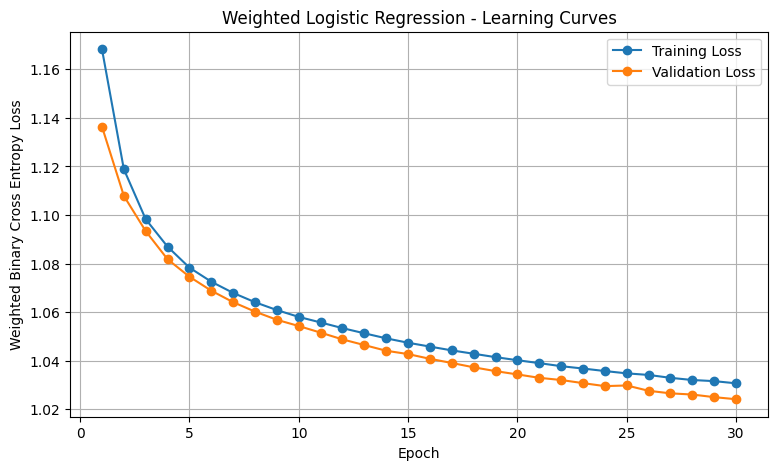

In [45]:
# Create a figure
plt.figure(figsize=(9, 5))

# Plot training loss
plt.plot(
    range(1, num_epochs + 1),
    weighted_training_losses,
    label="Training Loss",
    marker="o"
)

# Plot validation loss
plt.plot(
    range(1, num_epochs + 1),
    weighted_validation_losses,
    label="Validation Loss",
    marker="o"
)

# Add graph labels
plt.title("Weighted Logistic Regression - Learning Curves")
plt.xlabel("Epoch")
plt.ylabel("Weighted Binary Cross Entropy Loss")

plt.legend()
plt.grid(True)
plt.show()

In [46]:
# Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

# Set model to evaluation mode
weighted_model.eval()

# Generate validation predictions
with torch.no_grad():

    val_logits = weighted_model(X_val_tensor)

    # Convert logits into probabilities
    val_probabilities = torch.sigmoid(val_logits)

    # Convert probabilities into binary predictions
    val_predictions = (val_probabilities >= 0.5).int()

# Convert tensors into NumPy arrays
y_val_true = y_val_tensor.numpy().ravel().astype(int)
y_val_pred = val_predictions.numpy().ravel().astype(int)

# Calculate accuracy
val_accuracy = accuracy_score(
    y_val_true,
    y_val_pred
)

print("Validation Accuracy:", round(val_accuracy * 100, 2), "%")

# Calculate confusion matrix
print("\nValidation Confusion Matrix:")
print(confusion_matrix(y_val_true, y_val_pred))

# Generate classification report
print("\nValidation Classification Report:")
print(
    classification_report(
        y_val_true,
        y_val_pred,
        target_names=["no", "yes"],
        zero_division=0
    )
)

Validation Accuracy: 71.0 %

Validation Confusion Matrix:
[[4575 1813]
 [ 285  561]]

Validation Classification Report:
              precision    recall  f1-score   support

          no       0.94      0.72      0.81      6388
         yes       0.24      0.66      0.35       846

    accuracy                           0.71      7234
   macro avg       0.59      0.69      0.58      7234
weighted avg       0.86      0.71      0.76      7234



In [47]:
# Create an unweighted Logistic Regression model
control_model = WeightedLogisticRegressionModel(
    input_features=50
)

# Use ordinary Binary Cross-Entropy with logits
control_loss_function = nn.BCEWithLogitsLoss()

# Create a new optimizer
control_optimizer = optim.SGD(
    control_model.parameters(),
    lr=0.01
)

# Create training DataLoader
control_train_loader = DataLoader(
    TensorDataset(X_fit_tensor, y_fit_tensor),
    batch_size=256,
    shuffle=True
)

# Store training and validation losses
control_training_losses = []
control_validation_losses = []

# Train for 30 epochs
for epoch in range(30):

    control_model.train()
    total_loss = 0.0

    for batch_features, batch_labels in control_train_loader:

        control_optimizer.zero_grad()

        logits = control_model(batch_features)

        loss = control_loss_function(
            logits,
            batch_labels
        )

        loss.backward()
        control_optimizer.step()

        total_loss += loss.item() * batch_features.size(0)

    epoch_loss = total_loss / len(X_fit_tensor)

    # Evaluate on validation data
    control_model.eval()

    with torch.no_grad():
        val_logits = control_model(X_val_tensor)

        val_loss = control_loss_function(
            val_logits,
            y_val_tensor
        )

    control_training_losses.append(epoch_loss)
    control_validation_losses.append(val_loss.item())

    if (epoch + 1) % 5 == 0:
        print(
            f"Epoch [{epoch + 1}/30], "
            f"Training Loss: {epoch_loss:.4f}, "
            f"Validation Loss: {val_loss.item():.4f}"
        )

print("\nUnweighted control model training completed!")

Epoch [5/30], Training Loss: 0.3380, Validation Loss: 0.3392
Epoch [10/30], Training Loss: 0.3309, Validation Loss: 0.3325
Epoch [15/30], Training Loss: 0.3265, Validation Loss: 0.3280
Epoch [20/30], Training Loss: 0.3236, Validation Loss: 0.3248
Epoch [25/30], Training Loss: 0.3212, Validation Loss: 0.3223
Epoch [30/30], Training Loss: 0.3194, Validation Loss: 0.3202

Unweighted control model training completed!


In [48]:
# Put the control model in evaluation mode
control_model.eval()

# Generate predictions
with torch.no_grad():

    # Get raw logits
    control_logits = control_model(X_val_tensor)

    # Convert logits into probabilities
    control_probabilities = torch.sigmoid(control_logits)

    # Apply the 0.5 classification threshold
    control_predictions = (
        control_probabilities >= 0.5
    ).int()

# Convert tensors into NumPy arrays
control_y_pred = control_predictions.numpy().ravel().astype(int)

# Calculate accuracy
control_accuracy = accuracy_score(
    y_val_true,
    control_y_pred
)

print("Control Model Validation Accuracy:",
      round(control_accuracy * 100, 2), "%")

# Confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_val_true, control_y_pred))

# Classification report
print("\nClassification Report:")
print(
    classification_report(
        y_val_true,
        control_y_pred,
        target_names=["no", "yes"],
        zero_division=0
    )
)

Control Model Validation Accuracy: 88.55 %

Confusion Matrix:
[[6383    5]
 [ 823   23]]

Classification Report:
              precision    recall  f1-score   support

          no       0.89      1.00      0.94      6388
         yes       0.82      0.03      0.05       846

    accuracy                           0.89      7234
   macro avg       0.85      0.51      0.50      7234
weighted avg       0.88      0.89      0.84      7234



In [49]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Store predictions from both models
model_predictions = {
    "Unweighted": control_y_pred,
    "Weighted": y_val_pred
}

# Store evaluation results
comparison_results = []

for model_name, predictions in model_predictions.items():

    comparison_results.append({
        "Model": model_name,

        "Accuracy": accuracy_score(
            y_val_true, predictions
        ),

        "Precision": precision_score(
            y_val_true, predictions, zero_division=0
        ),

        "Recall": recall_score(
            y_val_true, predictions, zero_division=0
        ),

        "F1 Score": f1_score(
            y_val_true, predictions, zero_division=0
        )
    })

# Create comparison table
comparison_df = pd.DataFrame(comparison_results)

display(
    comparison_df.round(4)
)

,Model,Accuracy,Precision,Recall,F1 Score
0,Unweighted,0.8855,0.8214,0.0272,0.0526
1,Weighted,0.7100,0.2363,0.6631,0.3484


In [50]:
# Convert validation probabilities into a NumPy array
val_probs = val_probabilities.numpy().ravel()

# Define thresholds to investigate
thresholds = [0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50]

# Store experiment results
threshold_results = []

for threshold in thresholds:

    # Convert probabilities into predictions
    predictions = (val_probs >= threshold).astype(int)

    # Calculate evaluation metrics
    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_val_true, predictions),
        "Precision": precision_score(y_val_true, predictions, zero_division=0),
        "Recall": recall_score(y_val_true, predictions, zero_division=0),
        "F1 Score": f1_score(y_val_true, predictions, zero_division=0),
        "Predicted Yes": predictions.sum()
    })

# Create comparison table
threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))

,Threshold,Accuracy,Precision,Recall,F1 Score,Predicted Yes
0,0.10,0.1275,0.1182,1.0000,0.2114,7158
1,0.15,0.1557,0.1212,0.9953,0.2161,6946
2,0.20,0.2317,0.1292,0.9704,0.2281,6354
3,0.25,0.2972,0.1367,0.9421,0.2387,5832
4,0.30,0.3630,0.1454,0.9113,0.2507,5304
5,0.40,0.5263,0.1734,0.8097,0.2856,3951
6,0.50,0.7100,0.2363,0.6631,0.3484,2374


In [51]:
# Generate more threshold values
fine_thresholds = np.arange(0.05, 0.96, 0.01)

# Store results
fine_results = []

for threshold in fine_thresholds:

    # Generate predictions
    predictions = (val_probs >= threshold).astype(int)

    # Calculate metrics
    fine_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val_true, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val_true, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_val_true, predictions, zero_division=0
        ),
        "Predicted Yes": predictions.sum()
    })

# Create a DataFrame
fine_threshold_df = pd.DataFrame(fine_results)

# Find the 10 best thresholds by F1-score
top_thresholds = fine_threshold_df.sort_values(
    by=["F1 Score", "Recall"],
    ascending=False
).head(10)

display(top_thresholds.round(4))

# Identify the best F1 threshold
best_threshold = fine_threshold_df.loc[
    fine_threshold_df["F1 Score"].idxmax()
]

print("\nBest threshold:", round(best_threshold["Threshold"], 2))
print("Best F1-score:", round(best_threshold["F1 Score"], 4))

,Threshold,Precision,Recall,F1 Score,Predicted Yes
60,0.65,0.4566,0.4102,0.4321,760
58,0.63,0.4145,0.4468,0.4300,912
59,0.64,0.4318,0.4232,0.4275,829
55,0.60,0.3626,0.5130,0.4249,1197
61,0.66,0.4658,0.3865,0.4225,702
54,0.59,0.3502,0.5307,0.4220,1282
57,0.62,0.3888,0.4610,0.4218,1003
56,0.61,0.3714,0.4846,0.4205,1104
53,0.58,0.3367,0.5485,0.4173,1378
52,0.57,0.3249,0.5638,0.4123,1468



Best threshold: 0.65
Best F1-score: 0.4321


In [52]:
# Lock the threshold selected using validation data
selected_threshold = float(best_threshold["Threshold"])

# Put the weighted model into evaluation mode
weighted_model.eval()

# Generate predictions on the untouched test set
with torch.no_grad():

    # Get raw model outputs (logits)
    test_logits = weighted_model(X_test_v2_tensor)

    # Convert logits into sigmoid scores
    test_probabilities = torch.sigmoid(test_logits)

    # Apply our selected threshold
    test_predictions = (
        test_probabilities >= selected_threshold
    ).int()

# Convert tensors into NumPy arrays
y_test_true = (
    y_test_v2_tensor.numpy().ravel().astype(int)
)

y_test_final_pred = (
    test_predictions.numpy().ravel().astype(int)
)

# Calculate final metrics
print("Selected threshold:", selected_threshold)

print(
    "\nFinal Test Accuracy:",
    round(accuracy_score(y_test_true, y_test_final_pred) * 100, 2),
    "%"
)

print("\nFinal Confusion Matrix:")
print(confusion_matrix(y_test_true, y_test_final_pred))

print("\nFinal Classification Report:")
print(
    classification_report(
        y_test_true,
        y_test_final_pred,
        target_names=["no", "yes"],
        zero_division=0
    )
)

Selected threshold: 0.6500000000000001

Final Test Accuracy: 87.01 %

Final Confusion Matrix:
[[7443  542]
 [ 633  425]]

Final Classification Report:
              precision    recall  f1-score   support

          no       0.92      0.93      0.93      7985
         yes       0.44      0.40      0.42      1058

    accuracy                           0.87      9043
   macro avg       0.68      0.67      0.67      9043
weighted avg       0.87      0.87      0.87      9043

